# Build an agent with tool-calling superpowers 🦸 using smolagents
_Authored by: [Aymeric Roucher](https://huggingface.co/m-ric)_

This notebook demonstrates how you can use [**smolagents**](https://huggingface.co/docs/smolagents/index) to build awesome **agents**!

What are **agents**? Agents are systems that are powered by an LLM and enable the LLM (with careful prompting and output parsing) to use specific *tools* to solve problems.

These *tools* are basically functions that the LLM couldn't perform well by itself: for instance for a text-generation LLM like [Llama-3-70B](https://huggingface.co/meta-llama/Meta-Llama-3-70B-Instruct), this could be an image generation tool, a web search tool, a calculator...

What is **smolagents**? It's an library that provides building blocks to build your own agents! Learn more about it in the [documentation](https://huggingface.co/docs/smolagents/index).

Let's see how to use it, and which use cases it can solve.

Run the line below to install required dependencies:

In [ ]:
# Environment for week14: Extra: agents (smolagents) and masked text diffusion (LLaDA).
# Colab or a fresh virtualenv: run this cell once. Locally: `uv sync --group week14` in the repo root instead.
%pip install -q "torch>=2.4,<3" "transformers>=4.56,<5" "numpy>=1.26" "huggingface-hub>=0.25" "smolagents>=1.10" "ddgs>=9"

Let's login in order to call the HF Inference API:

In [3]:
from huggingface_hub import notebook_login

notebook_login()

## 1. 🏞️ Multimodal + 🌐 Web-browsing assistant

For this use case, we want to show an agent that browses the web and is able to generate images.

To build it, we simply need to have two tools ready: image generation and web search.
- For image generation, we load a tool from the Hub that uses the HF Inference API (Serverless) to generate images using Stable Diffusion.
- For the web search, we use a built-in tool.

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tool.py:   0%|          | 0.00/635 [00:00<?, ?B/s]

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Generate me a photo of the car that James bond drove in the latest movie.                                       │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen3-4B-Instruct-2507 ────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  prompt = "James Bond's car from the latest Bond movie, high-res, photorealistic, detailed, spy vehicle, sleek    
  and modern"                                                                                                      
  image = image_generator(prompt)                                                                                  
  final_answer(image)                                                                                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: <PIL.WebPImagePlugin.WebPImageFile image mode=RGB size=512x512 at 0x78BCFA2DFE90>

[Step 1: Duration 4.31 seconds| Input tokens: 2,159 | Output tokens: 124]

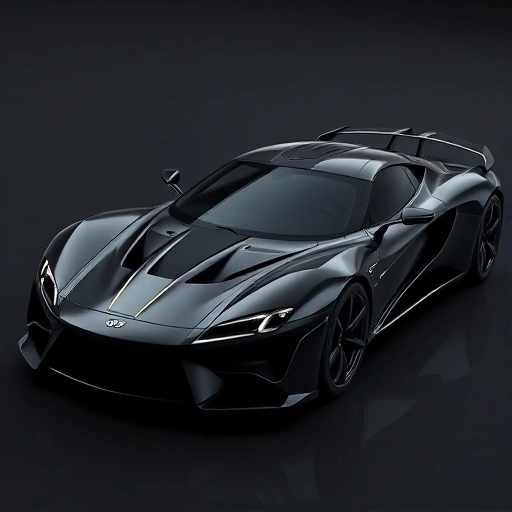

In [4]:
from smolagents import load_tool, CodeAgent, InferenceClientModel, DuckDuckGoSearchTool

# Import tool from Hub
image_generation_tool = load_tool("m-ric/text-to-image", trust_remote_code=True)


search_tool = DuckDuckGoSearchTool()

model = InferenceClientModel("Qwen/Qwen3-4B-Instruct-2507")
# Initialize the agent with both tools
agent = CodeAgent(
    tools=[image_generation_tool, search_tool], model=model
)

# Run it!
result = agent.run(
    "Generate me a photo of the car that James bond drove in the latest movie.",
)
result

![Image of an Aston Martin DB5](https://huggingface.co/datasets/huggingface/cookbook-images/resolve/main/agents_db5.png)

In [11]:
from smolagents import CodeAgent, InferenceClientModel, DuckDuckGoSearchTool

model = InferenceClientModel("Qwen/Qwen3-4B-Instruct-2507")
agent = CodeAgent(
    tools=[DuckDuckGoSearchTool()],
    model=model,
)

# Now the agent can search the web!
result = agent.run("What is the current weather in Paris?")
print(result)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ What is the current weather in Paris?                                                                           │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen3-4B-Instruct-2507 ────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  weather_info = web_search("current weather in Paris")                                                            
  print(weather_info)                                                                                              
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Execution logs:
## Search Results

[Go Phone use in Canada and loss of Rollover Data on plan 
change](https://forums.att.com/conversations/wireless-account/go-phone-use-in-canada-and-loss-of-rollover-data-on-p
lan-change/5df00885bad5f2f606b55d2e)
Aug 26, 2015 · Switching rate plans would not result in a loss of your current account balance, however any cost 
associated with the rate plan (E.G. $60 Monthly Plan) would be deducted …

[No call for install appointment 3 weeks following new service 
order](https://forums.att.com/conversations/att-internet-installation/no-call-for-install-appointment-3-weeks-follo
wing-new-service-order/62fb94bab2b2e606ecc2f12f)
Aug 16, 2022 · Considerly current labor shortages all industries are facing, this would be an unknown factor. In 
all case, you should consider having (2) ISPs if working from home, as …

[Internet pricing - AT&T Community 
Forums](https://forums.att.com/conversations/att-fiber-account/internet-pricing/5e971f4df6e8ee4322055635)
Apr 15, 2020 · When I visit the Internet page on att.com it shows a current promotion for 1000MBPS of $49.99 with a
line crossed through the 'regular price' of $70. I'm paying $100 per …

[Early upgrade options - AT&T Community 
Forums](https://forums.att.com/conversations/wireless-account/early-upgrade-options/5df00b8abad5f2f606e59340)
Sep 11, 2015 · Pay early termination fee on current phone plan (I'm 12 months into a 2 yr contract on an iPhone 6),
keep my number, Get 6S plus from Apple under upgrade program, Bring it to …

[turn denon receiver on and off using uverse s20 remote | AT&T 
...](https://forums.att.com/conversations/uverse-tv-equipment/turn-denon-receiver-on-and-off-using-uverse-s20-remot
e/5fe3a63435994b51065d5359)
Dec 23, 2020 · My current uverse s20 receiver will turn on my tv and denon receiver plus control the volume. I was 
able to program the new s20 remote to turn the TV on and off and control …

[Valued customer - AT&T Community 
Forums](https://forums.att.com/conversations/watching-uverse-tv/valued-customer/5df02e63bad5f2f6060f8e40)
Sep 12, 2019 · My question is why don't at&t try harder to keep current valud customers with incentives when 
nearing the end of a promotional process. I have been with your cable …

[False Advertisement In My County | AT&T Community 
Forums](https://forums.att.com/conversations/att-fiber-ordering/false-advertisement-in-my-county/60ca259d22f33063d3
3bf83a)
Jun 16, 2021 · I suspect that the Broadband Now map is more current and more accurate than the AT&T map you linked.
If you zoom down on the Broadband Now map, you can get street-level …

[Disabling of LTE with Unlimited data plans while 
tethering](https://forums.att.com/conversations/data-messaging-features-internet-tethering/disabling-of-lte-with-un
limited-data-plans-while-tethering/5defce3fbad5f2f606b2e0cc)
Jun 1, 2016 · The current front runner that meets my requirements is a non-Sprint, non-T-mobile cellphone service 
provider that competes with AT&T, Sprint and T-mobile but has less total …

[Upgrade price changed when finalized? - AT&T Community 
Forums](https://forums.att.com/conversations/wireless-billing/upgrade-price-changed-when-finalized/5e783c82e0718159
07e99117)
Mar 23, 2020 · Hello! Tonight I was looking about how I could get more hot spot on my plan. I saw this other plan 
in the first picture said it was 130 dollars under that blue best choice banner. My …

[Still have not received S21+ Android 13/One UI 5 update | Page 2 
…](https://forums.att.com/conversations/samsung/still-have-not-received-s21-android-13one-ui-5-update/6377a73cbf186
27a7a7ba747?page=2)
Nov 18, 2022 · From what I understand the S21+ Android 13/One UI 5 update has been out for a few days now and I 
still have not received the update. My phone is an AT&T branded …

Out: None

[Step 1: Duration 1.89 seconds| Input tokens: 2,083 | Output tokens: 58]

...

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 3 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  final_answer("Clear sky, around 13-16°C")                                                                        
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: Clear sky, around 13-16°C

[Step 3: Duration 2.14 seconds| Input tokens: 9,528 | Output tokens: 225]

Clear sky, around 13-16°C




## 2. 💻 Debug Python code
Since the CodeAgent has a built-in Python code interpreter, we can use it to debug our faulty Python script!

In [7]:
from smolagents import CodeAgent

agent = CodeAgent(tools=[], model=InferenceClientModel("Qwen/Qwen3-4B-Instruct-2507"))

code = """
numbers=[0, 1, 2]

for i in range(4):
    print(numbers(i))
"""

final_answer = agent.run(
    "I have some code that creates a bug: please debug it, then run it to make sure it works and return the final code",
    additional_args=dict(code=code)
)

╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ I have some code that creates a bug: please debug it, then run it to make sure it works and return the final    │
│ code                                                                                                            │
│ You have been provided with these additional arguments, that you can access directly using the keys as          │
│ variables:                                                                                                      │
│ {'code': '\nnumbers=[0, 1, 2\]\n\nfor i in range(4):\n    print(numbers(i))\n'}.                                │
│                                                                                                                 │
╰─ InferenceClientModel - Qwen/Qwen3-4B-Instruct-2507 ────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

─ Executing parsed code: ──────────────────────────────────────────────────────────────────────────────────────── 
  # Fixed code                                                                                                     
  code = 'numbers = [0, 1, 2]\nfor i in range(len(numbers)):\n    print(numbers[i])'                               
  final_answer(code)                                                                                               
 ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Final answer: numbers = [0, 1, 2]
for i in range(len(numbers)):
    print(numbers[i])

[Step 1: Duration 2.47 seconds| Input tokens: 2,105 | Output tokens: 151]

As you can see, the agent tried the given code, gets an error, analyses the error, corrects the code and returns it after veryfing that it works!

And the final code is the corrected code:

In [8]:
print(final_answer)

numbers = [0, 1, 2]
for i in range(len(numbers)):
    print(numbers[i])


## ➡️ Conclusion

The use cases above should give you a glimpse into the possibilities of our Agents framework!

For more advanced usage, read the [documentation](https://huggingface.co/docs/smolagents/index).

All feedback is welcome, it will help us improve the framework! 🚀

# Diffusion models

In [ ]:
import torch
import numpy as np
import torch.nn.functional as F

from transformers import AutoTokenizer, AutoModel


def add_gumbel_noise(logits, temperature):
    if temperature == 0:
        return logits
    logits = logits.to(torch.float64)
    noise = torch.rand_like(logits, dtype=torch.float64)
    gumbel_noise = (- torch.log(noise)) ** temperature
    return logits.exp() / gumbel_noise


def get_num_transfer_tokens(mask_index, steps):
    mask_num = mask_index.sum(dim=1, keepdim=True)

    base = mask_num // steps
    remainder = mask_num % steps

    num_transfer_tokens = torch.zeros(mask_num.size(0), steps, device=mask_index.device, dtype=torch.int64) + base

    for i in range(mask_num.size(0)):
        num_transfer_tokens[i, :remainder[i]] += 1

    return num_transfer_tokens


@ torch.no_grad()
def generate(model, prompt, steps=128, gen_length=128, block_length=128, temperature=0.,
             cfg_scale=0., remasking='low_confidence', mask_id=156895):
    x = torch.full((1, prompt.shape[1] + gen_length), mask_id, dtype=torch.long).to(model.device)
    x[:, :prompt.shape[1]] = prompt.clone()
    prompt_index = (x != mask_id)

    assert gen_length % block_length == 0
    num_blocks = gen_length // block_length
    assert steps % num_blocks == 0
    steps = steps // num_blocks

    for num_block in range(num_blocks):
        block_mask_index = (x[:, prompt.shape[1] + num_block * block_length: prompt.shape[1] + (num_block + 1) * block_length:] == mask_id)
        num_transfer_tokens = get_num_transfer_tokens(block_mask_index, steps)
        for i in range(steps):
            mask_index = (x == mask_id)
            if cfg_scale > 0.:
                un_x = x.clone()
                un_x[prompt_index] = mask_id
                x_ = torch.cat([x, un_x], dim=0)
                logits = model(x_).logits
                logits, un_logits = torch.chunk(logits, 2, dim=0)
                logits = un_logits + (cfg_scale + 1) * (logits - un_logits)
            else:
                logits = model(x).logits

            logits_with_noise = add_gumbel_noise(logits, temperature=temperature)
            x0 = torch.argmax(logits_with_noise, dim=-1) # b, l

            if remasking == 'low_confidence':
                p = F.softmax(logits, dim=-1)
                x0_p = torch.squeeze(
                    torch.gather(p, dim=-1, index=torch.unsqueeze(x0, -1)), -1) # b, l
            elif remasking == 'random':
                x0_p = torch.rand((x0.shape[0], x0.shape[1]), device=x0.device)
            else:
                raise NotImplementedError(remasking)

            x0_p[:, prompt.shape[1] + (num_block + 1) * block_length:] = -np.inf

            x0 = torch.where(mask_index, x0, x)
            confidence = torch.where(mask_index, x0_p, -np.inf)

            transfer_index = torch.zeros_like(x0, dtype=torch.bool, device=x0.device)
            for j in range(confidence.shape[0]):
                _, select_index = torch.topk(confidence[j], k=num_transfer_tokens[j, i])
                transfer_index[j, select_index] = True
            x[transfer_index] = x0[transfer_index]

    return x


device = 'cuda'
model = AutoModel.from_pretrained('inclusionAI/LLaDA-MoE-7B-A1B-Instruct', trust_remote_code=True, dtype=torch.bfloat16).to(device).eval()
tokenizer = AutoTokenizer.from_pretrained('inclusionAI/LLaDA-MoE-7B-A1B-Instruct', trust_remote_code=True)

prompt = "Lily can run 12 kilometers per hour for 4 hours. After that, she runs 6 kilometers per hour. How many kilometers can she run in 8 hours?"
m = [
    {"role": "system", "content": "You are a helpful AI assistant."},
    {"role": "user", "content": prompt}
]
prompt = tokenizer.apply_chat_template(m, add_generation_prompt=True, tokenize=False)

input_ids = tokenizer(prompt)['input_ids']
input_ids = torch.tensor(input_ids).to(device).unsqueeze(0)

text = generate(model, input_ids, steps=128, gen_length=128, block_length=32, temperature=0., cfg_scale=0., remasking='low_confidence')
print(tokenizer.batch_decode(text[:, input_ids.shape[1]:], skip_special_tokens=False)[0])
